# Pre-entrega 4 · Parte 3: mejora del modelo, interpretación y conclusiones

**Objetivo:** mejorar el K-Means base de la Parte 2 (k = 2) con PCA y selección de variables, comparar con las mismas métricas, interpretar los clusters en la escala original y responder la pregunta del proyecto: **¿cómo se relacionan los estilos/niveles de juego con ser Top 4 y con que el DT sea británico o extranjero?**

**Entradas** (generadas en las Partes 1 y 2, rama `clustering`): `features_clustering.csv`, `tabla_equipo_temporada.csv`, `clusters_kmeans_base.csv`. Además se usa `tabla_temporadas.csv` para corregir puntos y posición de dos temporadas (sección 1).

**Resumen de resultados**
- La mejora (sin `precision`/`rojas` + PCA 85%) sube el Silhouette de **0,257 a 0,354** y mejora Davies-Bouldin y Calinski-Harabasz, manteniendo grupos estables y de tamaño razonable. La partición resultante es idéntica a la del modelo base (ARI = 1): se ven más separados, pero son los mismos grupos.
- Con k = 2 los grupos son **"Dominante"** y **"Resto de la liga"**: separan nivel más que estilo. Pedir más clusters (k = 4) solo recupera la época de medición (cambio de criterio de 2013/14), no estilos.
- DBSCAN (clase 21) no encuentra grupos separados por densidad: los equipos forman un continuo, lo que apoya usar K-Means solo para separar niveles.
- El cluster Dominante concentra **102 de los 104 Top 4**. Entre los DT registrados, los británicos están más en el cluster "Resto", pero esa relación está confundida con la época y el tamaño del club, y la muestra es chica.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from itertools import combinations
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

SEMILLA = 42
AZUL, NARANJA, GRIS, VERDE = "#2a78d6", "#eb6834", "#8a8a85", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 100, "axes.titleweight": "bold"})
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", NARANJA])

RUTA = next(p for p in ["../data/processed", "data/processed"] if os.path.exists(p))
X = pd.read_csv(f"{RUTA}/features_clustering.csv")            # 10 variables escaladas (Parte 1)
tabla = pd.read_csv(f"{RUTA}/tabla_equipo_temporada.csv")      # misma cantidad de filas y mismo orden
base = pd.read_csv(f"{RUTA}/clusters_kmeans_base.csv")         # clusters del modelo base (Parte 2)
temporadas = pd.read_csv(f"{RUTA}/tabla_temporadas.csv")       # posición/puntos con los 90 partidos recuperados
assert len(X) == len(tabla) == len(base) and (tabla["equipo"] == base["equipo"]).all()
print("Variables del modelo:", list(X.columns)); print("Filas:", len(X))

Variables del modelo: ['tiros', 'goles_a_favor', 'corners', 'precision', 'conversion', 'goles_en_contra', 'tiros_en_contra', 'faltas', 'amarillas', 'rojas']
Filas: 520


## 1. Dos correcciones de datos antes de interpretar

Antes de mejorar el modelo hay que revisar las columnas que se usan **solo para interpretar** (`puntos`, `posicion`, `top4`, `es_britanico`), porque la interpretación depende de ellas.

**a) Puntos y posición de 2003/04 y 2004/05.** La unión de CSV con `on_bad_lines='skip'` perdió 90 partidos de esas dos temporadas (los equipos figuran con 32–35 partidos en vez de 38). Eso no afecta a los promedios por partido de las variables de juego, pero sí a `puntos` y `posicion`. Se reemplazan por los valores de `tabla_temporadas.csv`, reconstruida desde los CSV originales (`src/construir_tabla_temporadas.py`), con el desempate oficial de la Premier.

**b) `es_britanico`.** En `dataset_final_modelo.csv`, cuando el DT figura como *"DT No Registrado"* el valor de `es_britanico` está **imputado según el año** (1 hasta 2004, 0 desde 2005); no es un dato real. Se marca qué filas tienen DT registrado para usar la nacionalidad **solo** en esas.

In [2]:
# a) puntos / posición / top4 corregidos (cruce por temporada y equipo)
nombres = {"Tottenham Hotspur": "Tottenham"}
clave = tabla.assign(equipo_m=tabla["equipo"].replace(nombres))
corr = temporadas[["temp_inicio", "equipo", "puntos_totales", "posicion", "top4"]].rename(
    columns={"equipo": "equipo_m", "puntos_totales": "puntos_corr", "posicion": "posicion_corr", "top4": "top4_corr"})
clave = clave.merge(corr, on=["temp_inicio", "equipo_m"], how="left")
print("Filas sin cruce:", int(clave["puntos_corr"].isna().sum()))
print("Filas con puntos distintos a los de la tabla original:", int((clave["puntos"] != clave["puntos_corr"]).sum()),
      "(todas en", sorted(clave.loc[clave["puntos"] != clave["puntos_corr"], "temporada"].unique()), ")")
print("Top 4 por temporada tras la corrección:", clave.groupby("temp_inicio")["top4_corr"].sum().unique())

# b) DT registrado
tabla["puntos"], tabla["posicion"], tabla["top4"] = clave["puntos_corr"], clave["posicion_corr"], clave["top4_corr"]
tabla["dt_registrado"] = (tabla["dt_principal"] != "DT No Registrado").astype(int)
print(f"\nFilas con DT registrado: {tabla.dt_registrado.sum()} de {len(tabla)} ({tabla.dt_registrado.mean():.0%})")
tabla.loc[tabla.dt_registrado == 1, "es_britanico"].value_counts().rename({0: "extranjero", 1: "británico"})

Filas sin cruce: 0
Filas con puntos distintos a los de la tabla original: 39 (todas en ['2003-04', '2004-05'] )
Top 4 por temporada tras la corrección: [4]

Filas con DT registrado: 158 de 520 (30%)


,count
es_britanico,
extranjero,113
británico,45


## 2. Punto de partida: el modelo base

Se reproduce el modelo de la Parte 2 (K-Means `k-means++`, `n_init=10`, **k = 2**) y se calculan las **mismas métricas**: inercia, Silhouette, Davies-Bouldin (menor es mejor), Calinski-Harabasz (mayor es mejor), tamaño del cluster más chico y estabilidad (ARI medio entre 20 semillas).

In [3]:
def ajustar(Z, k, semilla=SEMILLA):
    return KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=semilla).fit(Z)

def evaluar(Z, k, n_semillas=20):
    Z = np.asarray(Z); m = ajustar(Z, k); et = m.labels_
    corridas = [ajustar(Z, k, s).labels_ for s in range(n_semillas)]
    ari = [adjusted_rand_score(a, b) for a, b in combinations(corridas, 2)]
    return {"k": k, "inercia": m.inertia_, "silhouette": silhouette_score(Z, et),
            "davies_bouldin": davies_bouldin_score(Z, et), "calinski_harabasz": calinski_harabasz_score(Z, et),
            "% cluster mínimo": 100 * np.bincount(et).min() / len(et), "ARI medio": np.mean(ari)}

K_BASE = 2
res_base = evaluar(X, K_BASE)
pd.Series(res_base).round(3).to_frame("modelo base (10 variables, k=2)")

,"modelo base (10 variables, k=2)"
k,2.000
inercia,3792.271
silhouette,0.257
davies_bouldin,1.489
calinski_harabasz,192.287
% cluster mínimo,31.154
ARI medio,0.998


## 3. Mejoras

Se prueban **dos mejoras** y su combinación. Cada una con su criterio:

**Mejora A · PCA antes de K-Means.** Se conservan los primeros componentes hasta explicar **entre 85% y 90%** de la varianza. Criterio: las variables de juego están correlacionadas entre sí (tiros, córners y goles suben juntos); PCA las resume en pocos ejes independientes y elimina parte del ruido.

**Mejora B · Sacar variables que no ayudan a separar los grupos.** Criterio: para cada variable se mide cuánta de su varianza explican los clusters del modelo base (η²: 0 = no separa nada, 1 = separa perfecto). Se descartan las que casi no separan.

Componentes para 85%: 5 (acumulada 87.6%) | para 90%: 6 (acumulada 91.9%)


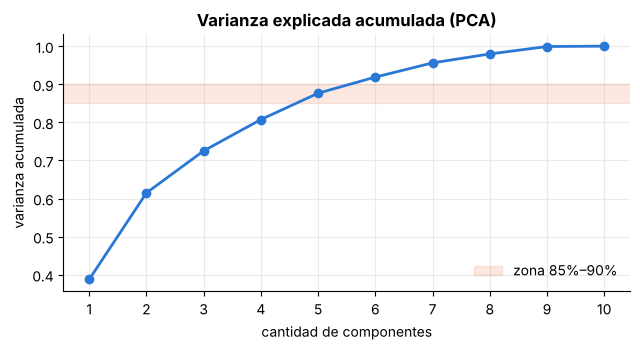

In [4]:
# Mejora A: ¿cuántos componentes para 85% - 90%?
pca_full = PCA().fit(X)
acum = pca_full.explained_variance_ratio_.cumsum()
n85, n90 = int(np.searchsorted(acum, .85) + 1), int(np.searchsorted(acum, .90) + 1)
print(f"Componentes para 85%: {n85} (acumulada {acum[n85-1]:.1%}) | para 90%: {n90} (acumulada {acum[n90-1]:.1%})")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(range(1, len(acum) + 1), acum, "-o", color=AZUL, lw=2)
ax.axhspan(.85, .90, color=NARANJA, alpha=.15, label="zona 85%–90%")
ax.set(title="Varianza explicada acumulada (PCA)", xlabel="cantidad de componentes", ylabel="varianza acumulada", xticks=range(1, 11))
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

In [5]:
# Mejora B: η² de cada variable respecto de los clusters del modelo base
et_base = ajustar(X, K_BASE).labels_
def eta2(v, et):
    return sum(len(v[et == g]) * (v[et == g].mean() - v.mean()) ** 2 for g in np.unique(et)) / ((v - v.mean()) ** 2).sum()
eta = pd.Series({c: eta2(X[c].values, et_base) for c in X}).sort_values()

# Y un segundo motivo para mirar 'precision': ¿cambió su medición en 2013/14?
despues = (tabla["temp_inicio"] >= 2013).values
cambio_era = pd.Series({c: X[c][despues].mean() - X[c][~despues].mean() for c in X})   # en desvíos estándar
resumen = pd.DataFrame({"η² (separa los clusters base)": eta, "salto 2013/14 (en desvíos)": cambio_era[eta.index]}).round(3)
resumen

,η² (separa los clusters base),salto 2013/14 (en desvíos)
precision,0.005,-1.869
rojas,0.007,-0.446
amarillas,0.076,0.566
conversion,0.091,1.510
faltas,0.091,-0.966
goles_en_contra,0.417,0.231
tiros_en_contra,0.429,0.476
corners,0.461,-0.365
tiros,0.530,0.475
goles_a_favor,0.600,0.185


**Lectura.** `precision` y `rojas` prácticamente no separan los grupos (η² ≈ 0). Además, `precision` (tiros al arco / tiros) tiene un **salto enorme en 2013/14**, que es el cambio de criterio con que football-data registra los tiros al arco: esa variable mide *la época*, no el estilo. Por eso se descartan **`precision`** y **`rojas`**.

Se podría ir más lejos y quedarse solo con las 5 variables de mayor η² (todas de *nivel*: tiros, goles, córners), pero eso subiría el Silhouette a costa de eliminar toda la información de disciplina y efectividad, y el modelo dejaría de poder describir estilos. Se deja como alternativa descartada.

In [6]:
VARS_B = [c for c in X.columns if c not in ["precision", "rojas"]]
Z = {}
Z["Base (10 variables)"] = X.values
Z["A: PCA 85%"] = PCA(n85, random_state=SEMILLA).fit_transform(X)
Z["B: sin precision y rojas"] = X[VARS_B].values
n85_b = int(np.searchsorted(PCA().fit(X[VARS_B]).explained_variance_ratio_.cumsum(), .85) + 1)
Z["A+B: sin precision/rojas + PCA 85%"] = PCA(n85_b, random_state=SEMILLA).fit_transform(X[VARS_B])

filas = []
for nombre, M in Z.items():
    for k in range(2, 6):
        filas.append({"modelo": nombre, **evaluar(M, k)})
comp_k = pd.DataFrame(filas)
comp_k.pivot(index="k", columns="modelo", values="silhouette").round(3)

modelo,A+B: sin precision/rojas + PCA 85%,A: PCA 85%,B: sin precision y rojas,Base (10 variables)
k,,,,
2,0.354,0.294,0.312,0.257
3,0.268,0.285,0.226,0.241
4,0.247,0.266,0.202,0.223
5,0.233,0.246,0.181,0.202


### ¿Qué pasa con el cluster extra de k = 3 (el artefacto de 2013/14)?

En el modelo base, k = 3 partía a los equipos "no élite" en *antes vs. después de 2013/14*. Se verifica si las mejoras corrigen eso (si un cluster tiene casi solo equipos de una época, está midiendo la medición y no el estilo).

In [7]:
era = np.where(despues, "2013/14 en adelante", "hasta 2012/13")
filas = []
for nombre, M in Z.items():
    et = ajustar(M, 3).labels_
    ct = pd.crosstab(et, era)
    filas.append({"modelo": nombre, "k=3: mayor concentración de una época en un cluster": (ct.max(axis=1) / ct.sum(axis=1)).max()})
pd.DataFrame(filas).set_index("modelo").round(3)

,k=3: mayor concentración de una época en un cluster
modelo,
Base (10 variables),0.995
A: PCA 85%,0.995
B: sin precision y rojas,0.944
A+B: sin precision/rojas + PCA 85%,0.946


## 4. Comparación: modelo base vs. mejorados

Criterio acordado: **el modelo mejorado gana si sube el Silhouette sin que los grupos dejen de tener sentido** (se agregan los chequeos de tamaño mínimo ≥ 5% y estabilidad ARI ≥ 0,90).

Con k = 2 (el elegido en la Parte 2):

In [8]:
k2 = comp_k[comp_k.k == 2].set_index("modelo").drop(columns="k")
k2["Δ Silhouette vs. base"] = k2["silhouette"] - k2.loc["Base (10 variables)", "silhouette"]
k2["cumple tamaño ≥5%"] = k2["% cluster mínimo"] >= 5
k2["estable (ARI ≥ 0,90)"] = k2["ARI medio"] >= .90
k2.round(3)

,inercia,silhouette,davies_bouldin,calinski_harabasz,% cluster mínimo,ARI medio,Δ Silhouette vs. base,cumple tamaño ≥5%,"estable (ARI ≥ 0,90)"
modelo,,,,,,,,,
Base (10 variables),3792.271,0.257,1.489,192.287,31.154,0.998,0.000,True,True
A: PCA 85%,3150.066,0.294,1.340,231.452,30.769,0.993,0.037,True,True
B: sin precision y rojas,2758.729,0.312,1.254,263.113,30.769,0.998,0.055,True,True
A+B: sin precision/rojas + PCA 85%,2255.841,0.354,1.119,321.684,31.154,1.000,0.097,True,True


In [9]:
# Se vuelve a aplicar el criterio de elección de k de la Parte 2 sobre cada modelo:
# mejor Silhouette entre los k válidos; si otro k queda a menos de 0,02, se desempata por interpretabilidad.
filas = []
for nombre in Z:
    d = comp_k[(comp_k.modelo == nombre) & (comp_k["% cluster mínimo"] >= 5) & (comp_k["ARI medio"] >= .90)].sort_values("silhouette", ascending=False)
    mejor = d.iloc[0]; cerca = d[(d.k != mejor.k) & (mejor.silhouette - d.silhouette < .02)]
    filas.append({"modelo": nombre, "k elegido (mejor Silhouette)": int(mejor.k), "Silhouette": round(mejor.silhouette, 3),
                  "otros k a menos de 0,02": list(cerca.k.astype(int))})
pd.DataFrame(filas).set_index("modelo")

,k elegido (mejor Silhouette),Silhouette,"otros k a menos de 0,02"
modelo,,,
Base (10 variables),2,0.257,[3]
A: PCA 85%,2,0.294,[3]
B: sin precision y rojas,2,0.312,[]
A+B: sin precision/rojas + PCA 85%,2,0.354,[]


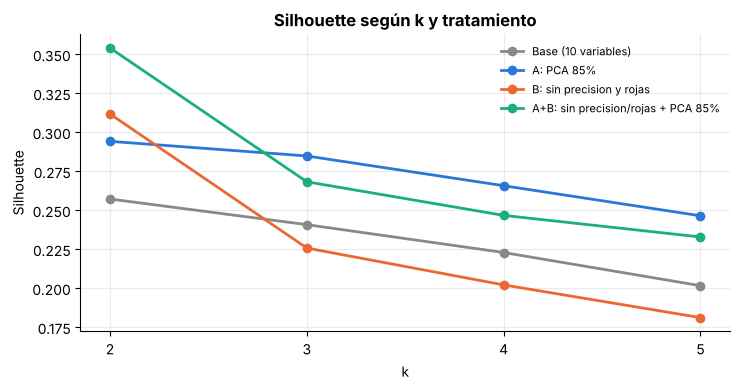

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
colores = [GRIS, AZUL, NARANJA, VERDE]
for (nombre, g), c in zip(comp_k.groupby("modelo", sort=False), colores):
    ax.plot(g.k, g.silhouette, "-o", color=c, lw=2, label=nombre)
ax.set(title="Silhouette según k y tratamiento", xlabel="k", ylabel="Silhouette", xticks=range(2, 6))
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

In [11]:
# Modelo final: sin precision/rojas + PCA 85%, k = 2
K_FINAL = 2
Z_final = Z["A+B: sin precision/rojas + PCA 85%"]
etiq = ajustar(Z_final, K_FINAL).labels_

# Los números de cluster son arbitrarios: se nombra por el promedio de puntos (el cluster con más puntos es el "dominante")
orden = pd.Series(tabla["puntos"].groupby(etiq).mean()).sort_values(ascending=False).index
nombre_k2 = {orden[0]: "Dominante", orden[1]: "Resto de la liga"}
tabla["cluster_final"] = pd.Series(etiq).map(nombre_k2).values

print("ARI entre el modelo base y el final:", round(adjusted_rand_score(base["cluster_base"], etiq), 3))
print(tabla["cluster_final"].value_counts().to_string())

ARI entre el modelo base y el final: 1.0
cluster_final
Resto de la liga    358
Dominante           162


**Resultado.** Las tres variantes **superan al modelo base** en Silhouette (0,257 → 0,294 con PCA, 0,312 sin `precision`/`rojas`, **0,354 con ambas**), y también mejoran Davies-Bouldin (menor) y Calinski-Harabasz (mayor). Todas cumplen el tamaño mínimo (el cluster más chico es ≈ 31%) y son estables (ARI ≥ 0,99). Con el criterio de elección de k de la Parte 2, **k = 2 sigue siendo el elegido** en todos los modelos; en los dos mejorados ya no hay otro k a menos de 0,02, así que no hace falta desempatar.

**Los grupos no dejan de tener sentido:** el modelo final separa a los mismos equipos que el base (ARI entre ambos = 1,0, ver abajo), es decir que la mejora hace los grupos más compactos y mejor separados sin cambiar quién es quién. La inercia no se compara entre modelos porque está en espacios de distinta dimensión.

**Dos aclaraciones honestas:**
- El Silhouette de modelos con distinta cantidad de variables no es estrictamente comparable. Se usa porque es el criterio acordado, y se apoya con Davies-Bouldin y Calinski-Harabasz, que dan la misma conclusión.
- Sacar `precision` reduce el artefacto de 2013/14 en k = 3 pero no lo elimina (un cluster sigue con 94% de una sola época). Es una razón más para quedarse con k = 2.

**Modelo final:** sin `precision` ni `rojas`, PCA con 5 componentes (87,6% de la varianza) y k = 2.

## 5. Interpretación de los clusters

### 5.1 Perfil de cada cluster

Promedios **en la escala original** (por partido), no en la escala estandarizada. El heatmap muestra cuánto se aleja cada cluster del promedio de la liga (en desvíos estándar; naranja = por encima, azul = por debajo) con el valor original anotado. `puntos`, `top4` y `es_britanico` **no se usaron** para formar los clusters.

Época de cada cluster (si fuera un artefacto de medición, un cluster tendría casi solo una época):
col_0             2013/14 en adelante  hasta 2012/13
cluster_final                                       
Dominante                          87             75
Resto de la liga                  173            185


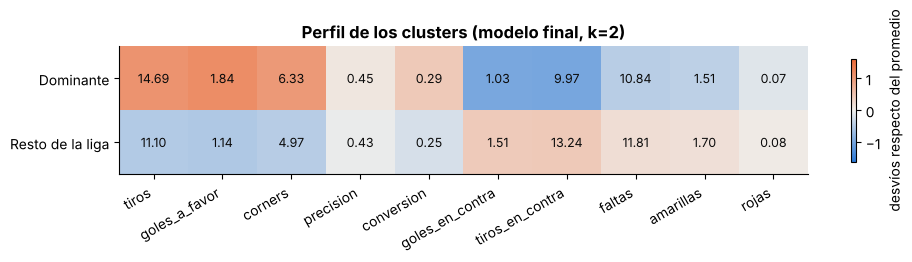

,tiros,goles_a_favor,corners,precision,conversion,goles_en_contra,tiros_en_contra,faltas,amarillas,rojas,equipos,puntos,pct_top4
cluster_final,,,,,,,,,,,,,
Dominante,14.69,1.84,6.33,0.45,0.29,1.03,9.97,10.84,1.51,0.07,162,72.1,63.0
Resto de la liga,11.10,1.14,4.97,0.43,0.25,1.51,13.24,11.81,1.70,0.08,358,43.3,0.6


In [12]:
VARS = list(X.columns)
def perfil(df, col):
    return df.groupby(col)[VARS].mean()

def heatmap_perfil(col, titulo, orden_filas):
    orig = perfil(tabla, col).loc[orden_filas]
    z = X.groupby(tabla[col].values).mean().loc[orden_filas]
    fig, ax = plt.subplots(figsize=(10, 1.0 + .8 * len(orden_filas)))
    im = ax.imshow(z.values, cmap=DIVERGENTE, vmin=-1.6, vmax=1.6, aspect="auto")
    ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=30, ha="right"); ax.set_yticks(range(len(orden_filas))); ax.set_yticklabels(orden_filas)
    ax.grid(False)
    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            ax.text(j, i, f"{orig.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color="#0b0b0b")
    ax.set_title(titulo); fig.colorbar(im, ax=ax, label="desvíos respecto del promedio", shrink=.8)
    plt.tight_layout(); plt.show()
    return orig

ORD2 = ["Dominante", "Resto de la liga"]
orig2 = heatmap_perfil("cluster_final", "Perfil de los clusters (modelo final, k=2)", ORD2)
ctx = tabla.groupby("cluster_final").agg(equipos=("equipo", "size"), puntos=("puntos", "mean"), pct_top4=("top4", "mean"))
ctx["pct_top4"] = (100 * ctx["pct_top4"]).round(1)
print("Época de cada cluster (si fuera un artefacto de medición, un cluster tendría casi solo una época):")
print(pd.crosstab(tabla["cluster_final"], np.where(despues, "2013/14 en adelante", "hasta 2012/13")).loc[ORD2].to_string())
pd.concat([orig2.round(2), ctx.round(1)], axis=1).loc[ORD2]

Los nombres salen de leer el perfil:
- **Dominante:** más tiros, goles y córners; menos goles y tiros en contra; menos faltas y amarillas. Es el equipo que controla el partido.
- **Resto de la liga:** lo contrario.

Ningún cluster concentra una sola época (la tabla de arriba), así que no es un artefacto de la medición. Pero con k = 2 el modelo separa sobre todo **nivel** (los que mandan vs. los demás) más que **estilo de juego**.

### 5.2 Diagnóstico: ¿aparecen estilos de juego si se piden más clusters?

Se prueba k = 4 con las 8 variables (sin `precision` ni `rojas`) **solo como diagnóstico**: no cumple el criterio de Silhouette y no reemplaza al modelo final. Los grupos se ordenan por puntos promedio.

Silhouette k=4 (8 variables): 0.202 (menor que el del modelo final)


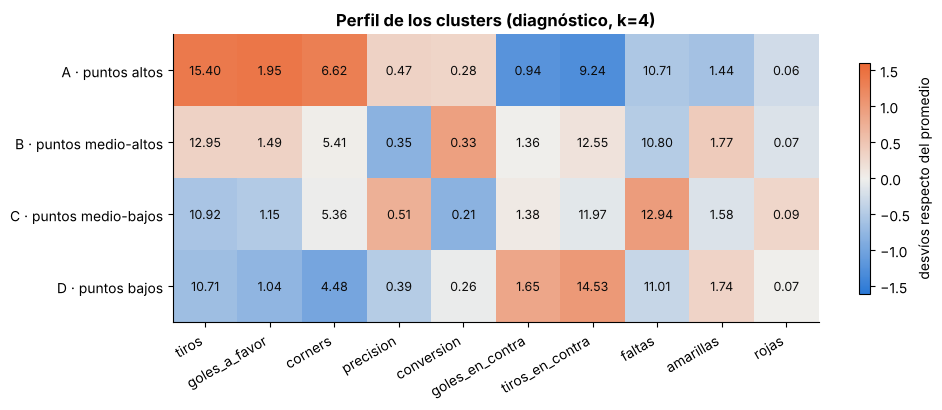

col_0,2013/14 en adelante,hasta 2012/13,% de la época más frecuente
cluster_k4,,,
A · puntos altos,47,60,56.1
B · puntos medio-altos,107,4,96.4
C · puntos medio-bajos,8,154,95.1
D · puntos bajos,98,42,70.0


In [13]:
et4 = ajustar(X[VARS_B], 4).labels_
rank4 = tabla["puntos"].groupby(et4).mean().sort_values(ascending=False).index
ORD4 = ["A · puntos altos", "B · puntos medio-altos", "C · puntos medio-bajos", "D · puntos bajos"]
tabla["cluster_k4"] = pd.Series(et4).map(dict(zip(rank4, ORD4))).values
print("Silhouette k=4 (8 variables):", round(silhouette_score(X[VARS_B], et4), 3), "(menor que el del modelo final)")
orig4 = heatmap_perfil("cluster_k4", "Perfil de los clusters (diagnóstico, k=4)", ORD4)

ct_era4 = pd.crosstab(tabla["cluster_k4"], np.where(despues, "2013/14 en adelante", "hasta 2012/13")).loc[ORD4]
ct_era4["% de la época más frecuente"] = (100 * ct_era4.max(axis=1) / ct_era4.sum(axis=1)).round(1)
ct_era4

**Resultado del diagnóstico:** los clusters de k = 4 siguen el orden de los puntos, pero **dos de ellos son casi de una sola época** (por ejemplo el grupo de puntos medio-altos es casi todo posterior a 2013/14 y el de medio-bajos casi todo anterior). Aunque se saquen `precision` y `rojas`, las variables que quedan (`conversion`, `faltas`, `tiros`) también cambiaron de nivel con el cambio de criterio de medición de 2013/14. Con estos datos los clusters finos reflejan la **época de medición**, no estilos de juego. Por eso **no se les pone nombre de estilo** (como "bloque bajo" o "físico") y el análisis de la pregunta del proyecto se hace con el modelo final de k = 2.

### 5.3 Comparación con DBSCAN (clase 21)

DBSCAN agrupa por **densidad** y marca como **ruido** a los puntos aislados (clase 21, diapositivas 10–12). Se usa la misma matriz que el modelo final (las 8 variables ya escaladas) y se siguen los pasos de la diapositiva 13:
- **Escalar antes**, porque epsilon es una distancia (ya están escaladas con `StandardScaler`).
- **`min_samples` ≥ cantidad de variables + 1** → 8 + 1 = **9**.
- **Epsilon:** gráfico de la distancia de cada punto a su vecino más cercano de orden `min_samples`, ordenada de menor a mayor; el **codo** sugiere el valor.

Comparación esperada (diapositiva 14): K-Means necesita elegir k y es sensible a outliers; DBSCAN no necesita k y detecta el ruido.

Distancias: mediana 1.56 | percentil 90: 2.02 | máximo: 2.85


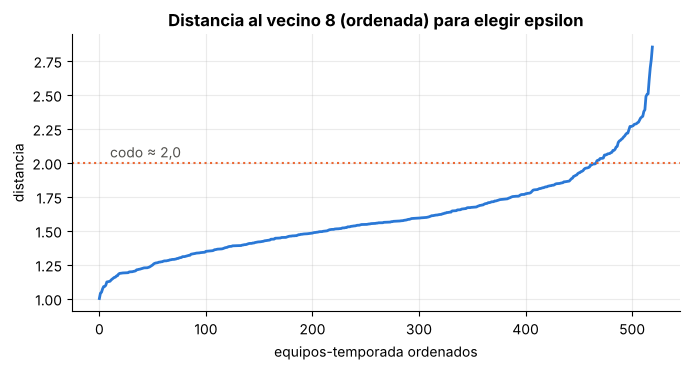

In [14]:
Zd = X[VARS_B].values                  # mismas 8 variables escaladas
MIN_PTS = len(VARS_B) + 1              # clase 21: al menos nº de variables + 1
dist, _ = NearestNeighbors(n_neighbors=MIN_PTS).fit(Zd).kneighbors(Zd)
kdist = np.sort(dist[:, -1])

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(len(kdist)), kdist, color=AZUL, lw=2)
ax.set(title=f"Distancia al vecino {MIN_PTS - 1} (ordenada) para elegir epsilon", xlabel="equipos-temporada ordenados", ylabel="distancia")
ax.axhline(2.0, ls=":", color=NARANJA); ax.text(10, 2.04, "codo ≈ 2,0", color="#52514e")
plt.tight_layout(); plt.show()
print("Distancias: mediana", kdist[len(kdist)//2].round(2), "| percentil 90:", np.quantile(kdist, .9).round(2), "| máximo:", kdist.max().round(2))

In [15]:
filas = []
for eps in [1.1, 1.3, 1.5, 1.7, 2.0]:
    et = DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(Zd)
    cl = [g for g in np.unique(et) if g != -1]; sin_ruido = et != -1
    sil = silhouette_score(Zd[sin_ruido], et[sin_ruido]) if len(cl) >= 2 else np.nan
    filas.append({"epsilon": eps, "clusters": len(cl), "% ruido": round(100 * (~sin_ruido).mean(), 1),
                  "tamaño de los clusters": np.bincount(et[sin_ruido]).tolist() if sin_ruido.any() else [], "Silhouette (sin ruido)": round(sil, 3)})
pd.DataFrame(filas).set_index("epsilon")

,clusters,% ruido,tamaño de los clusters,Silhouette (sin ruido)
epsilon,,,,
1.1,3,91.3,"[14, 7, 24]",0.208
1.3,2,57.5,"[208, 13]",0.396
1.5,2,21.3,"[387, 22]",0.247
1.7,1,6.3,[487],NaN
2.0,1,0.2,[519],NaN


In [16]:
# Con un epsilon más chico DBSCAN empieza a separar algo: ¿qué separa?
et_db = DBSCAN(eps=1.5, min_samples=MIN_PTS).fit_predict(Zd)
tabla["dbscan_eps15"] = np.where(et_db == -1, "ruido", np.where(et_db == 0, "cluster 0 (grande)", "cluster 1 (chico)"))
cmp_ = tabla.groupby("dbscan_eps15").agg(equipos=("equipo", "size"), puntos=("puntos", "mean"), pct_top4=("top4", "mean"))
cmp_["pct_top4"] = (100 * cmp_["pct_top4"]).round(1); cmp_["puntos"] = cmp_["puntos"].round(1)
print("DBSCAN (epsilon = 1,5, min_samples = 9) vs. K-Means final (k = 2):")
print(pd.crosstab(tabla["dbscan_eps15"], tabla["cluster_final"]).to_string())
cmp_

DBSCAN (epsilon = 1,5, min_samples = 9) vs. K-Means final (k = 2):
cluster_final       Dominante  Resto de la liga
dbscan_eps15                                   
cluster 0 (grande)         78               309
cluster 1 (chico)          22                 0
ruido                      62                49


,equipos,puntos,pct_top4
dbscan_eps15,,,
cluster 0 (grande),387,49.0,10.3
cluster 1 (chico),22,76.5,90.9
ruido,111,58.9,39.6


**Qué muestra DBSCAN:**
- Con el epsilon que marca el codo (≈ 2,0) **todo forma un solo cluster** y casi no hay ruido. Al achicarlo, aparecen grupos chicos y mucho ruido, pero ninguna partición estable y con sentido: **no hay huecos de densidad** entre los equipos; el nivel varía de forma continua. Es coherente con el Silhouette moderado (≈ 0,35) del modelo final.
- Con epsilon = 1,5 DBSCAN aísla 22 equipos-temporada del mejor nivel (91% Top 4, todos hasta 2012/13) y manda 111 a ruido. El ruido pega más en el cluster Dominante de K-Means (62 de 162, 38%) que en el Resto (49 de 358, 14%): los equipos de élite están más dispersos, en zonas menos densas. Es la diferencia de la diapositiva 14: DBSCAN trata a esos equipos como puntos aislados, mientras que K-Means los agrupa por cercanía.
- **Decisión:** se mantiene K-Means con k = 2 como modelo final. DBSCAN no aporta una partición mejor, pero sirve de contraste y confirma que los dos grupos de K-Means separan **niveles** sobre un continuo, no grupos naturalmente separados.

### 5.4 Los clusters en 2D (PCA)

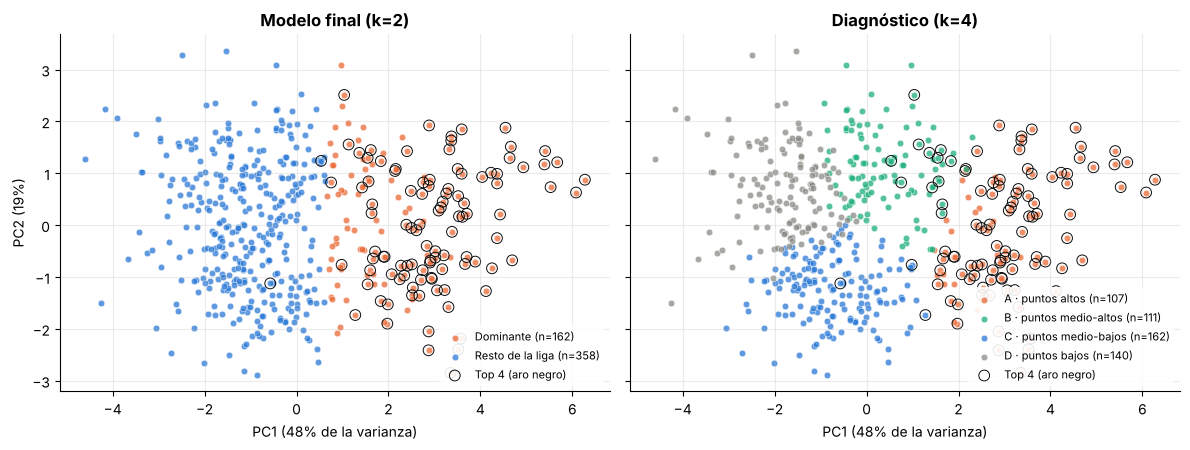

In [17]:
p2 = PCA(2, random_state=SEMILLA).fit(X[VARS_B]); P = p2.transform(X[VARS_B])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, col, orden, colores, titulo in [(axes[0], "cluster_final", ORD2, [NARANJA, AZUL], "Modelo final (k=2)"),
                                        (axes[1], "cluster_k4", ORD4, [NARANJA, VERDE, AZUL, GRIS], "Diagnóstico (k=4)")]:
    for nombre, c in zip(orden, colores):
        m = (tabla[col] == nombre).values
        ax.scatter(P[m, 0], P[m, 1], s=22, color=c, alpha=.75, edgecolor="white", linewidth=.4, label=f"{nombre} (n={m.sum()})")
    t4 = (tabla["top4"] == 1).values
    ax.scatter(P[t4, 0], P[t4, 1], s=60, facecolors="none", edgecolors="#0b0b0b", linewidth=.7, label="Top 4 (aro negro)")
    ax.set(title=titulo, xlabel=f"PC1 ({p2.explained_variance_ratio_[0]:.0%} de la varianza)")
    ax.legend(frameon=True, framealpha=.9, edgecolor="none", fontsize=8, loc="lower right")
axes[0].set_ylabel(f"PC2 ({p2.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()

## 6. La pregunta del proyecto: clusters, Top 4 y nacionalidad del DT

### 6.1 Clusters × Top 4

Aquí sí se pueden usar las 520 filas: `top4` no depende del DT. Se usa una **tabla cruzada** (cantidades y porcentaje por fila).

In [18]:
def tabla_cruzada(df, fila, columna, orden=None):
    ct = pd.crosstab(df[fila], df[columna]); pct = (100 * ct.div(ct.sum(axis=1), axis=0)).round(1)
    if orden is not None: ct, pct = ct.loc[orden], pct.loc[orden]
    return ct, pct

ct, pct = tabla_cruzada(tabla, "cluster_final", "top4", ORD2)
print("Cluster × Top 4 (cantidad de equipos-temporada)"); print(ct.rename(columns={0: "no Top 4", 1: "Top 4"}).to_string())
print("\n% por cluster"); print(pct.rename(columns={0: "no Top 4", 1: "Top 4"}).to_string())
print("\nTop 4 que cae en el cluster Dominante:", int(ct.loc["Dominante", 1]), "de", int(ct[1].sum()))

Cluster × Top 4 (cantidad de equipos-temporada)
top4              no Top 4  Top 4
cluster_final                    
Dominante               60    102
Resto de la liga       356      2

% por cluster
top4              no Top 4  Top 4
cluster_final                    
Dominante             37.0   63.0
Resto de la liga      99.4    0.6

Top 4 que cae en el cluster Dominante: 102 de 104


### 6.2 Clusters × nacionalidad del DT

Solo con equipos-temporada con **DT registrado** (la nacionalidad del resto está imputada por año y daría una relación falsa). Es una muestra chica y **sesgada hacia los clubes grandes** (en cada temporada están registrados sobre todo los 5–7 equipos de arriba), así que hay que leerla con cautela.

In [19]:
reg = tabla[tabla["dt_registrado"] == 1].copy()
reg["origen_dt"] = reg["es_britanico"].map({1: "británico", 0: "extranjero"})
print(f"Equipos-temporada con DT registrado: {len(reg)} | clusters (k=2): {reg.cluster_final.value_counts().to_dict()}")

ct, pct = tabla_cruzada(reg, "cluster_final", "origen_dt", ORD2)
print("\nCluster × origen del DT (cantidad)"); print(ct.to_string()); print("\n% por cluster"); print(pct.to_string())

ct_t, pct_t = tabla_cruzada(reg, "origen_dt", "top4")
print("\nOrigen del DT × Top 4 (cantidad)"); print(ct_t.rename(columns={0: "no Top 4", 1: "Top 4"}).to_string())
print("\n% por origen"); print(pct_t.rename(columns={0: "no Top 4", 1: "Top 4"}).to_string())

# La misma relación DENTRO del cluster dominante, para separar el efecto del nivel del club
dom = reg[reg.cluster_final == "Dominante"]
ct_d, pct_d = tabla_cruzada(dom, "origen_dt", "top4")
print("\nDentro del cluster Dominante: Top 4 según origen del DT"); print(ct_d.rename(columns={0: "no Top 4", 1: "Top 4"}).to_string()); print(pct_d.rename(columns={0: "no Top 4", 1: "Top 4"}).to_string())

Equipos-temporada con DT registrado: 158 | clusters (k=2): {'Dominante': 124, 'Resto de la liga': 34}

Cluster × origen del DT (cantidad)
origen_dt         británico  extranjero
cluster_final                          
Dominante                28          96
Resto de la liga         17          17

% por cluster
origen_dt         británico  extranjero
cluster_final                          
Dominante              22.6        77.4
Resto de la liga       50.0        50.0

Origen del DT × Top 4 (cantidad)
top4        no Top 4  Top 4
origen_dt                  
británico         27     18
extranjero        38     75

% por origen
top4        no Top 4  Top 4
origen_dt                  
británico       60.0   40.0
extranjero      33.6   66.4

Dentro del cluster Dominante: Top 4 según origen del DT
top4        no Top 4  Top 4
origen_dt                  
británico         10     18
extranjero        22     74
top4        no Top 4  Top 4
origen_dt                  
británico       35.7   64.3
ex

Con tablas de pocas filas (34 equipos-temporada en "Resto", 28 DT británicos en "Dominante") hay que mirar los **porcentajes junto con las cantidades**: una diferencia de pocos casos mueve mucho el porcentaje.

### 6.3 Evolución a lo largo de las temporadas

Equipos del cluster Dominante por época:
cluster_final    Dominante  Resto de la liga
era                                         
2000/01–2012/13         75               185
2013/14–2025/26         87               173


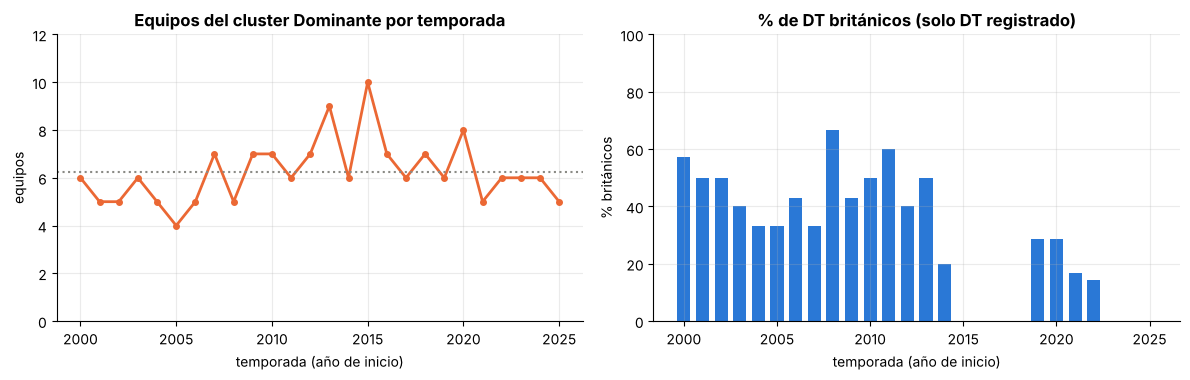

británicos  total  % británico
era             cluster_final                                   
2000/01–2012/13 Dominante                 23     61         37.7
                Resto de la liga          13     17         76.5
2013/14–2025/26 Dominante                  5     63          7.9
                Resto de la liga           4     17         23.5

In [20]:
era_lab = pd.cut(tabla["temp_inicio"], bins=[1999, 2012, 2025], labels=["2000/01–2012/13", "2013/14–2025/26"])
tabla["era"] = era_lab
reg["era"] = tabla.loc[reg.index, "era"]
print("Equipos del cluster Dominante por época:"); print(pd.crosstab(tabla["era"], tabla["cluster_final"])[ORD2].to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
por_temp = tabla.groupby(["temp_inicio", "cluster_final"]).size().unstack(fill_value=0)[ORD2]
axes[0].plot(por_temp.index, por_temp["Dominante"], "-o", color=NARANJA, lw=2, ms=4)
axes[0].set(title="Equipos del cluster Dominante por temporada", xlabel="temporada (año de inicio)", ylabel="equipos", ylim=(0, 12))
axes[0].axhline(por_temp["Dominante"].mean(), ls=":", color=GRIS)

brit = reg.groupby("temp_inicio")["es_britanico"].agg(["mean", "size"])
axes[1].bar(brit.index, 100 * brit["mean"], color=AZUL, width=.7)
axes[1].set(title="% de DT británicos (solo DT registrado)", xlabel="temporada (año de inicio)", ylabel="% británicos", ylim=(0, 100))
plt.tight_layout(); plt.show()

reg_era = reg.groupby(["era", "cluster_final"])["es_britanico"].agg(británicos="sum", total="size")
reg_era["% británico"] = (100 * reg_era["británicos"] / reg_era["total"]).round(1)
reg_era

### 6.4 Qué dicen los resultados

**Lectura de los resultados**
- **Top 4:** el cluster *Dominante* concentra 102 de los 104 Top 4 de las 26 temporadas (63% de sus equipos-temporada termina Top 4, contra 0,6% del resto). Es esperable, y sirve de validación: Top 4 **no** se usó para formar los clusters y aun así aparece.
- **Nacionalidad del DT (solo 158 filas con DT registrado):** los británicos son 23% de los equipos del cluster Dominante (28 de 124) y 50% del cluster Resto (17 de 34). Los equipos con DT británico terminan Top 4 el 40% de las veces (18 de 45) contra 66% de los extranjeros (75 de 113).
- **Pero esa asociación está confundida.** Dentro del cluster Dominante la diferencia de Top 4 baja a 64% (británicos, 18 de 28) vs. 77% (extranjeros, 74 de 96), con pocos casos. Una parte de lo anterior es que los clubes grandes contratan DT extranjeros (nivel del club), y otra que la época cambió: el porcentaje de DT británicos cayó en ambos grupos entre 2000/01–2012/13 y 2013/14–2025/26 (Dominante 38% → 8%, Resto 76% → 24%, este último con solo 17 casos por época).
- **Evolución:** la cantidad de equipos del cluster Dominante por temporada es estable (≈ 6 por año, sin tendencia clara), es decir que **lo que cambió no es cuántos equipos dominan sino quién los dirige**.

## 7. Conclusiones y limitaciones

**Modelo**
- La mejora combinada (sin `precision`/`rojas` + PCA 85%) sube el Silhouette de 0,257 a 0,354 y mejora las otras dos métricas sin perder estabilidad, pero **no cambia la partición**: sigue siendo "Dominante" vs. "Resto de la liga".
- **DBSCAN** (clase 21) confirma que los datos son un continuo sin huecos de densidad: con el epsilon que marca el codo todo forma un solo cluster, y achicarlo solo genera ruido o grupos chicos. K-Means con k = 2 sirve para separar **niveles**, no para descubrir grupos naturales.
- Con estas 10 variables y k = 2 el modelo describe **nivel**, no **estilos**. Con k = 4 los grupos extra reflejan principalmente la época de medición (cambio de criterio de football-data en 2013/14), por lo que no se pueden nombrar como estilos de juego sin engañar.

**Pregunta del proyecto**
- Los equipos "dominantes" casi coinciden con los que clasifican al Top 4, y entre los DT registrados los extranjeros están más presentes en ese grupo. **Eso es una asociación, no una relación causal**: el nivel del club y la época explican buena parte de la diferencia, y dentro del cluster dominante la nacionalidad del DT no muestra diferencia significativa en Top 4.
- Lo que sí se ve con claridad es el **cambio de época**: la presencia de DT británicos cae mucho desde 2013/14 incluso en el cluster dominante, mientras la cantidad de equipos dominantes no cambia.

**Limitaciones**
1. **DT registrado en solo 30% de las filas** (158 de 520), concentrado en los 5–7 equipos de arriba de cada temporada: la muestra está sesgada hacia clubes grandes y es chica (34 filas en "Resto"). Para el resto, `es_britanico` está imputado por año y no se usó.
2. **Cambio de medición en 2013/14** (tiros al arco, y arrastra a `precision`, `conversion`, `faltas`): limita cualquier comparación entre épocas con estas variables.
3. **Puntos y posición de 2003/04 y 2004/05** se corrigieron con la tabla reconstruida (la unión de CSV perdía 90 partidos). Las variables de juego (promedios por partido) quedaron como estaban.
4. Faltan variables de contexto que sí explican el nivel (presupuesto, valor de plantel).

**Siguientes pasos posibles:** completar el DT de todos los equipos-temporada, agregar variables de plantel y probar un ajuste por época.